# Wind forecast error analysis: January 2026

How accurate were Elexon's national wind forecasts (WINDFOR) against actual wind generation (FUELHH) for day-ahead purchases decided in January 2026?

This notebook uses the same data loading and forecast selection as the app (`backend/app`), so the numbers match the dashboard. Error is always `forecast − actual`: **positive means the forecast was too high**.

Percentiles here use pandas' default method, which differs slightly from the app's (Python `statistics`), so P10/P90 can differ by a few MW from the dashboard.

In [1]:
import sys

sys.path.insert(0, "../backend")

import matplotlib.pyplot as plt
import pandas as pd

from app.analysis import build_series
from app.config import MAX_HORIZON_HOURS, TARGET_END, TARGET_START
from app.elexon import get_actuals, get_forecasts

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

actuals, forecasts = get_actuals(), get_forecasts()


def scored(horizon: int) -> pd.DataFrame:
    """Hourly actual vs forecast pairs at the given horizon, with the error."""
    series = build_series(actuals, forecasts, horizon, TARGET_START, TARGET_END)
    df = pd.DataFrame([point.model_dump() for point in series]).dropna(subset=["forecast"])
    return df.assign(error=df.forecast - df.actual).set_index("time")


df = scored(24)
print(f"{len(actuals)} half-hourly actuals, {sum(map(len, forecasts.values()))} forecasts, {len(df)} scored hours at 24h")
df.describe().round(0)

1488 half-hourly actuals, 14383 forecasts, 744 scored hours at 24h


,actual,forecast,error
count,744.0,744.0,744.0
mean,11286.0,13022.0,1736.0
std,4209.0,4865.0,1657.0
min,1728.0,2292.0,-2655.0
25%,7999.0,9110.0,688.0
50%,11429.0,12826.0,1608.0
75%,15080.0,17714.0,2588.0
max,17805.0,21125.0,6804.0


## 1. Error distribution at 24h ahead

24 hours ahead is roughly when day-ahead purchases are made.

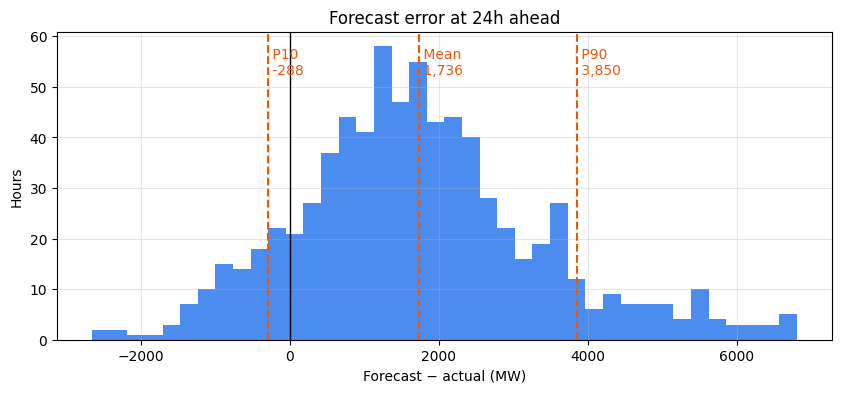

Over-forecast in 87% of hours
Mean error 1,736 MW = 15% of mean actual output
P10 -288 MW, median 1,608 MW, P90 3,850 MW


In [2]:
p10, p50, p90 = df.error.quantile([0.1, 0.5, 0.9])

ax = df.error.plot.hist(bins=40, color="#1f6feb", alpha=0.8)
for value, label in [(p10, "P10"), (df.error.mean(), "Mean"), (p90, "P90")]:
    ax.axvline(value, color="#e8590c", linestyle="--")
    ax.text(value, ax.get_ylim()[1] * 0.95, f" {label}\n {value:,.0f}", color="#e8590c", va="top")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Forecast error at 24h ahead", xlabel="Forecast − actual (MW)", ylabel="Hours")
plt.show()

print(f"Over-forecast in {(df.error > 0).mean():.0%} of hours")
print(f"Mean error {df.error.mean():,.0f} MW = {df.error.mean() / df.actual.mean():.0%} of mean actual output")
print(f"P10 {p10:,.0f} MW, median {p50:,.0f} MW, P90 {p90:,.0f} MW")

The distribution sits almost entirely to the right of zero: the forecast is **systematically too high**, not just noisy. That makes it biased, not merely uncertain, and a bias can be corrected.

## 2. Error by time of day

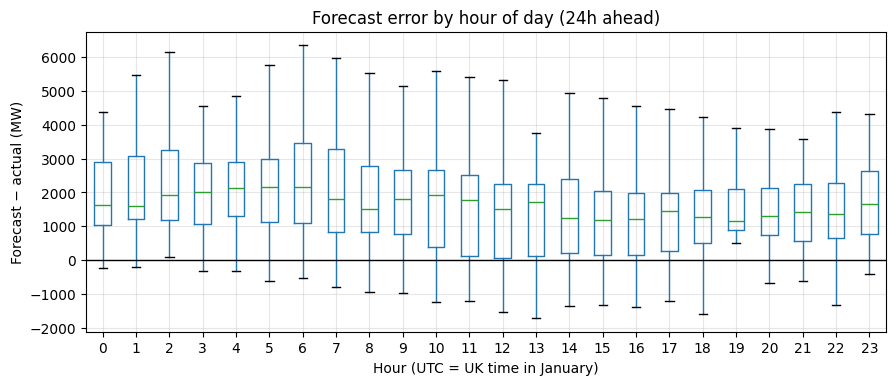

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mean,2075.0,2244.0,2363.0,2337.0,2349.0,2315.0,2285.0,2108.0,1917.0,1855.0,...,1303.0,1228.0,1241.0,1269.0,1316.0,1301.0,1359.0,1504.0,1562.0,1817.0
median,1638.0,1604.0,1918.0,2000.0,2131.0,2156.0,2165.0,1809.0,1517.0,1806.0,...,1242.0,1196.0,1228.0,1444.0,1262.0,1142.0,1300.0,1413.0,1368.0,1659.0


In [3]:
hourly = df.assign(hour=df.index.hour)
ax = hourly.boxplot(column="error", by="hour", showfliers=False, figsize=(10, 4))
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Forecast error by hour of day (24h ahead)", xlabel="Hour (UTC = UK time in January)", ylabel="Forecast − actual (MW)")
plt.suptitle("")
plt.show()

hourly.groupby("hour").error.agg(["mean", "median"]).T.round(0)

The over-forecast is largest **overnight and early morning** and smallest in the afternoon. Demand is lowest overnight, which is when the grid is most likely to tell wind farms to reduce output.

## 3. Error by wind level

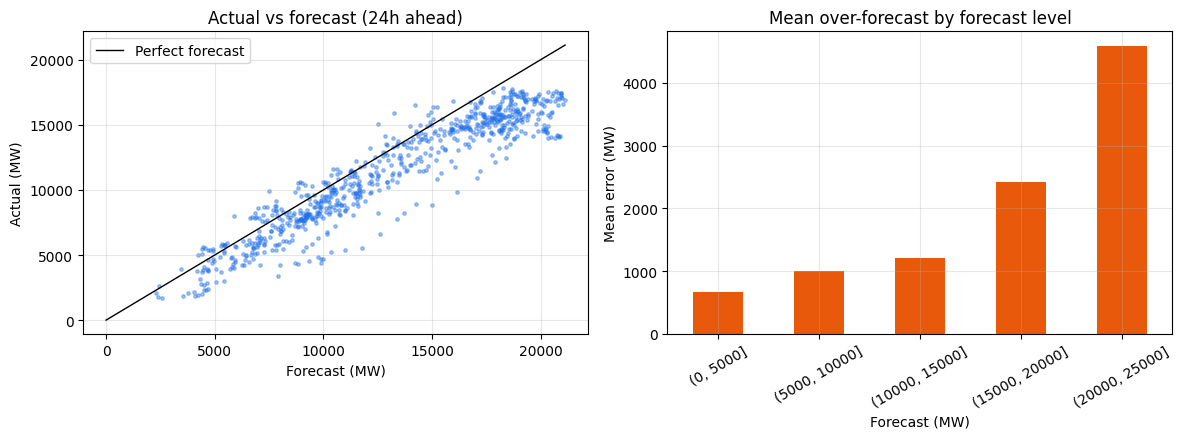

Max actual 17,805 MW, max forecast 21,125.0 MW


,count,mean
forecast,,
"(0, 5000]",38,675.0
"(5000, 10000]",205,996.0
"(10000, 15000]",205,1212.0
"(15000, 20000]",252,2426.0
"(20000, 25000]",44,4591.0


In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))

left.scatter(df.forecast, df.actual, s=6, alpha=0.4, color="#1f6feb")
limit = max(df.forecast.max(), df.actual.max())
left.plot([0, limit], [0, limit], color="black", linewidth=1, label="Perfect forecast")
left.set(title="Actual vs forecast (24h ahead)", xlabel="Forecast (MW)", ylabel="Actual (MW)")
left.legend()

levels = pd.cut(df.forecast, bins=[0, 5_000, 10_000, 15_000, 20_000, 25_000])
by_level = df.groupby(levels, observed=True).error.agg(["count", "mean"])
by_level["mean"].plot.bar(ax=right, color="#e8590c")
right.set(title="Mean over-forecast by forecast level", xlabel="Forecast (MW)", ylabel="Mean error (MW)")
right.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(f"Max actual {df.actual.max():,} MW, max forecast {df.forecast.max():,} MW")
by_level.round(0)

The bias grows sharply with wind level, and actual output flattens out at the top while the forecast keeps rising. That pattern is **consistent with curtailment**: wind farms being paid to cut output when the grid can't take it. In that case WINDFOR would forecast what the turbines could produce, while FUELHH measures what they were allowed to produce.

This is a hypothesis, not a confirmed cause. Confirming it would need Elexon's curtailment instructions to wind units (the BOALF dataset).

## 4. Error by forecast horizon

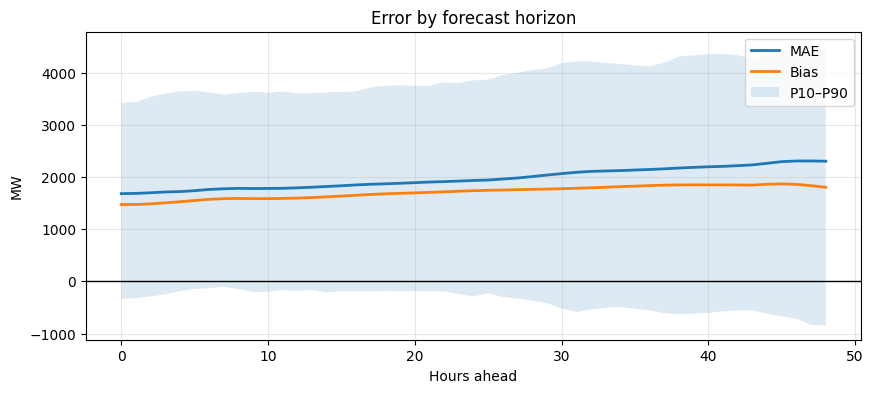

,hours,mae,bias,p10,p90
horizon,,,,,
0,744,1680.0,1471.0,-341.0,3420.0
6,744,1760.0,1571.0,-132.0,3621.0
12,744,1791.0,1595.0,-185.0,3605.0
24,744,1932.0,1736.0,-288.0,3850.0
36,744,2142.0,1834.0,-560.0,4121.0
48,589,2301.0,1801.0,-850.0,4513.0


In [5]:
rows = []
for horizon in range(MAX_HORIZON_HOURS + 1):
    error = scored(horizon).error
    rows.append({
        "horizon": horizon,
        "hours": len(error),
        "mae": error.abs().mean(),
        "bias": error.mean(),
        "p10": error.quantile(0.1),
        "p90": error.quantile(0.9),
    })
by_horizon = pd.DataFrame(rows).set_index("horizon")

ax = by_horizon[["mae", "bias"]].rename(columns={"mae": "MAE", "bias": "Bias"}).plot(linewidth=2)
ax.fill_between(by_horizon.index, by_horizon.p10, by_horizon.p90, alpha=0.15, label="P10–P90")
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Error by forecast horizon", xlabel="Hours ahead", ylabel="MW")
ax.legend()
plt.show()

by_horizon.loc[[0, 6, 12, 24, 36, 48]].round(0)

Error grows steadily with lead time, but the bias is already large at 0h. Most of the error is systematic at every horizon. At 48h, fewer hours are scored because forecasts aren't always published that far ahead.

## 5. Worst misses

In [6]:
df.reindex(df.error.abs().sort_values(ascending=False).index).head(10)

,actual,forecast,error
time,,,
2026-01-12 01:00:00+00:00,14048,20852.0,6804.0
2026-01-12 02:00:00+00:00,14123,20885.0,6762.0
2026-01-12 00:00:00+00:00,13954,20657.0,6703.0
2026-01-12 03:00:00+00:00,14171,20817.0,6646.0
2026-01-12 04:00:00+00:00,14193,20761.0,6568.0
2026-01-12 05:00:00+00:00,14091,20463.0,6372.0
2026-01-12 06:00:00+00:00,13989,20336.0,6347.0
2026-01-11 03:00:00+00:00,9825,16170.0,6345.0
2026-01-28 04:00:00+00:00,5570,11780.0,6210.0


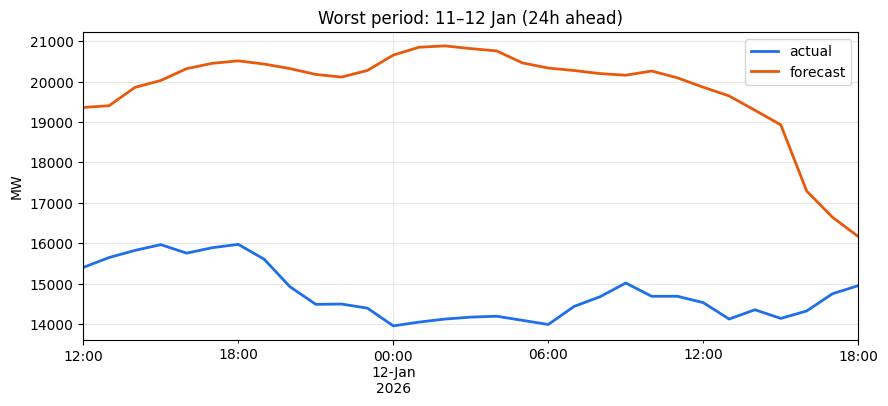

In [7]:
window = df.loc["2026-01-11 12:00":"2026-01-12 18:00"]
ax = window[["actual", "forecast"]].plot(linewidth=2, color=["#1f6feb", "#e8590c"])
ax.set(title="Worst period: 11–12 Jan (24h ahead)", xlabel="", ylabel="MW")
plt.show()

The seven largest misses all fall on the night of 11–12 Jan. The forecast held above 20 GW while actual output stayed flat at about 14 GW for hours. That flat line looks like a cap rather than a lack of wind, which again fits the curtailment explanation.

## Conclusions

1. **The forecast is biased high.** At 24h ahead it over-forecasts in most hours, by about 1.7 GW on average.
2. **The bias is concentrated on windy nights**, where it's consistent with (but not proven to be) curtailment.
3. **Error grows with lead time**, but bias is the bigger factor at every horizon.
4. **For day-ahead purchasing**, plan on about 1.7 GW less wind than forecast, and about 3.9 GW less to be covered in 9 out of 10 hours, with extra margin on windy nights.

**Limitations:** one winter month only, national totals only, and curtailment not yet confirmed. The next steps would be a full year of data and checking the curtailment hypothesis against BOALF.